## Lab - EDA Bivariate Analysis: Diving into Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
%matplotlib inline

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

1. **Crosstab Analysis**:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    
    - Are there categories where being a best-seller is more prevalent? 
    	
    	*Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order.*

In [3]:
df = pd.read_csv(r"amz_uk_price_prediction_dataset.csv")
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [38]:
cat = df.select_dtypes(exclude=np.number)
num = df.select_dtypes(include=np.number)
display(cat.shape, num.shape)
display(cat.columns)


(2443651, 4)

(2443651, 5)

Index(['asin', 'title', 'isBestSeller', 'category'], dtype='object')

In [87]:
best_sellers = pd.crosstab(df["category"],df["isBestSeller"])
display(best_sellers)
best_sellers.isna().sum()

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


isBestSeller
False    0
True     0
dtype: int64

In [40]:
best_sellers_prop = best_sellers[True] / (best_sellers[True] + best_sellers[False])*100

In [90]:
best_sellers

isBestSeller,False,True,best_seller_rate
category,,,
3D Printers,247,1,0.004032
3D Printing & Scanning,4065,2,0.000492
Abrasive & Finishing Products,245,5,0.020000
Action Cameras,1696,1,0.000589
Adapters,251,3,0.011811
...,...,...,...
Wind Instruments,243,7,0.028000
Window Treatments,234,5,0.020921
Women,17559,213,0.011985


In [89]:
best_sellers["best_seller_rate"] = best_sellers[True]/(best_sellers[True] + best_sellers[False])


best_sellers_prop = best_sellers_prop.sort_values(ascending=False)

best_seller_sorted = best_sellers.sort_values(by="best_seller_rate", ascending=False)

display(best_seller_sorted)
print(best_sellers_prop.count())
display(best_sellers_prop)

isBestSeller,False,True,best_seller_rate
category,,,
Grocery,9008,556,0.058135
Smart Home Security & Lighting,98,6,0.057692
Health & Personal Care,9017,552,0.057686
Mobile Phone Accessories,248,11,0.042471
Power & Hand Tools,8353,306,0.035339
...,...,...,...
Bedding Collections,6309,0,0.000000
CPUs,249,0,0.000000
"CD, Disc & Tape Players",8798,0,0.000000


296


category
Grocery                           5.813467
Smart Home Security & Lighting    5.769231
Health & Personal Care            5.768628
Mobile Phone Accessories          4.247104
Power & Hand Tools                3.533895
                                    ...   
Bedding Collections               0.000000
CPUs                              0.000000
CD, Disc & Tape Players           0.000000
Blank Media Cases & Wallets       0.000000
eBook Readers & Accessories       0.000000
Length: 296, dtype: float64

for Grocery, Smart HomeSEcurity, Health and Personal Care we can see that best sellers are more prevalent than for example for cpus, Bedding collections etc...

2. **Statistical Tests**:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.

In [92]:
best_sellers = best_sellers.drop(columns=["best_seller_rate"])

In [93]:
import scipy.stats as stats
from scipy.stats import chi2_contingency
_, chi2_pval, _, _ = chi2_contingency(best_sellers)
chi2_pval = float(chi2_pval)
print(type(chi2_pval))
print(f"P-value for Chi-squared test: {chi2_pval}")



<class 'float'>
P-value for Chi-squared test: 0.0


In [8]:
from scipy.stats.contingency import association
association(best_sellers, method='cramer')

0.1222829439760564

The cramer interpretation tells us that the association between isBestSeller and Category is very weak.

3. **Visualizations**:
	- Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

<Axes: xlabel='category'>

<Figure size 1200x600 with 0 Axes>

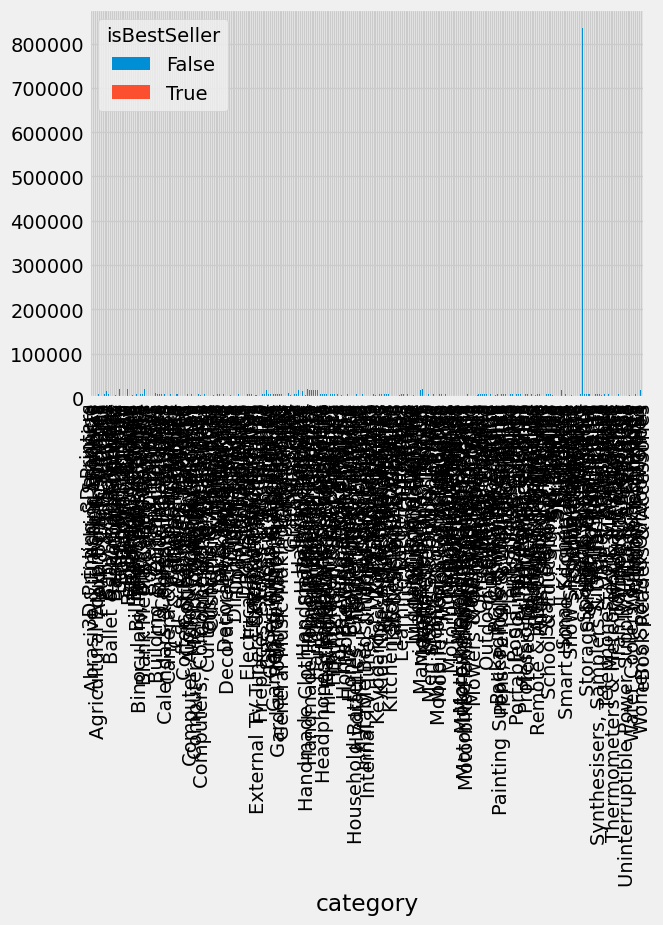

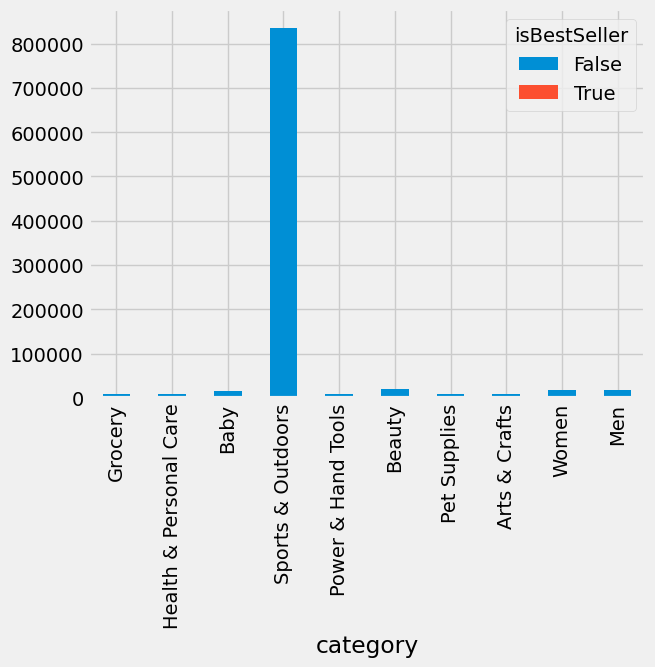

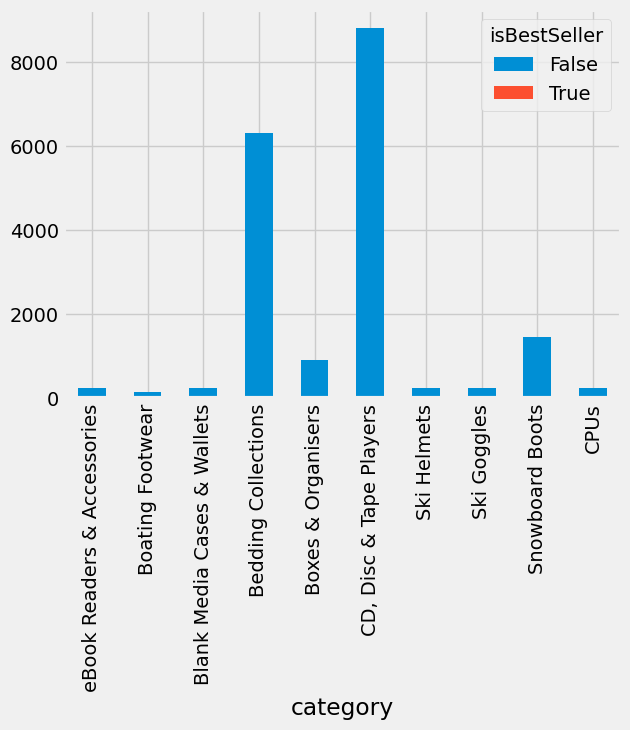

In [99]:
plt.figure(figsize=(12,6))
#plt.style.use("fivethirtyeight")
best_sellers.plot(kind = "bar",  stacked=True)
a = best_sellers.sort_values(by = True, ascending=False).head(10)
b = best_sellers.sort_values(by = True, ascending=True).head(10)

a.plot(kind="bar", stacked = True)
b.plot(kind ="bar", stacked = True)


### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

0. **Preliminary Step: Remove outliers in product prices.**

	For this purpose, we can use the IQR (Interquartile Range) method. Products priced below the first quartile minus 1.5 times the IQR or above the third quartile plus 1.5 times the IQR will be considered outliers and removed from the dataset. The next steps will be done with the dataframe without outliers.
	
	*Hint: you can check the last Check For Understanding at the end of the lesson EDA Bivariate Analysis for a hint on how to do this.*

In [10]:
display(num.columns)
display(num.price.isna().sum())

Index(['uid', 'stars', 'reviews', 'price', 'boughtInLastMonth'], dtype='object')

np.int64(0)

<Axes: xlabel='category', ylabel='price'>

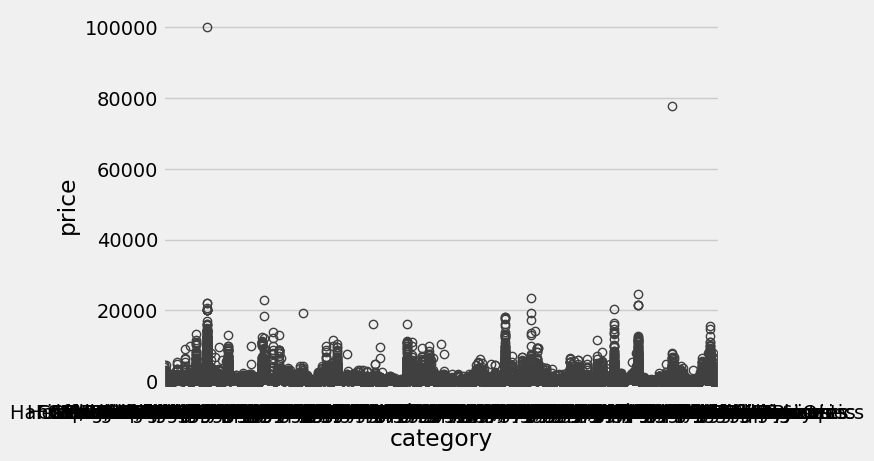

In [11]:
sns.boxplot(data=df, x="category", y="price")

In [12]:
price_ctable = pd.crosstab(cat["category"],num["price"])
display(price_ctable.shape)

(296, 82916)

In [13]:
#iqr = price_ctable.quantile(0.75) - price_ctable.quantile(0.25)  # Interquartile range
#iqr_threshold_upper = price_ctable.quantile(0.75) + 1.5 * iqr
#iqr_threshold_lower = price_ctable.quantile(0.25) - 1.5 * iqr
#print("upper threshold:", iqr_threshold_upper[0], "for category", price_ctable.columns[0])
#print("lower threshold:", iqr_threshold_lower)

In [29]:
def outlier_slayer(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1

    # Define bounds for the outliers
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Identify the outliers
    #outliers = data[(data < lower_bound) | (data > upper_bound)]
    # Remove outliers from the DataFrame
    cleaned_df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]

    return cleaned_df

In [30]:
cleaned_df = outlier_slayer(df, "price")

1. **Violin Plots**:
    - Use a violin plot to visualize the distribution of `price` across different product `categories`. Filter out the top 20 categories based on count for better visualization.
    - Which product category tends to have the highest median price? Don't filter here by top categories.

In [82]:
top_cats1 = cleaned_df['category'].value_counts(ascending=False).head(20).index
#top_cats1 = top_cats1[1:21]
display(top_cats1)
top_cats2= cleaned_df[cleaned_df["category"].isin(top_cats1)]

#top_cats1 = pd.DataFrame(top_cats1)
display(top_cats2)

Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts', 'Handmade Home Décor',
       'Luggage and travel gear', 'Women', 'Fragrances',
       'Handmade Kitchen & Dining', 'Handmade Artwork',
       'Handmade Home & Kitchen Products', 'Handmade Jewellery', 'Men',
       'Baby'],
      dtype='object', name='category')

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
19513,21072,B09477KHQ3,"Personalised Birthday Print Gift ""THE YEAR YOU...",4.5,763,7.99,False,900,Handmade Home & Kitchen Products
19514,21073,B0BSRFQYG8,Wax Melts 4 Bars | Build Your Own Box (Choose ...,3.9,117,6.49,True,800,Handmade Home & Kitchen Products
19515,21074,B09N9GVHV9,"Personalised Birthday Print Gift ""ON THE DAY/Y...",4.6,1155,8.99,True,600,Handmade Home & Kitchen Products
19516,21075,B0BRYGV7PQ,Fresh Wax Melts - Laundry Type Wax Melts - Str...,4.5,56,4.99,True,500,Handmade Home & Kitchen Products
19517,21076,B0B1JHB28R,Manta Makes Work Leaving Gifts | I Used to Wor...,4.7,261,9.95,True,400,Handmade Home & Kitchen Products
...,...,...,...,...,...,...,...,...,...
2429088,2806950,B0045I6SHW,Cannondale Men's Bibshort Dart Team Bike Shorts,0.0,0,99.67,False,0,Sports & Outdoors
2429089,2806951,B0045I6NZY,Cannondale Men's Baggy Fitness Bike Shorts,0.0,0,20.62,False,0,Sports & Outdoors
2429090,2806952,B003BLON3A,Pearl iZUMi Men's Phase Splice Knicker,4.3,3,59.86,False,0,Sports & Outdoors
2437153,2818782,B091HG57TP,Goodstoworld Boys Girls Tracksuit Bottoms 3D S...,4.2,554,14.99,False,0,Sports & Outdoors


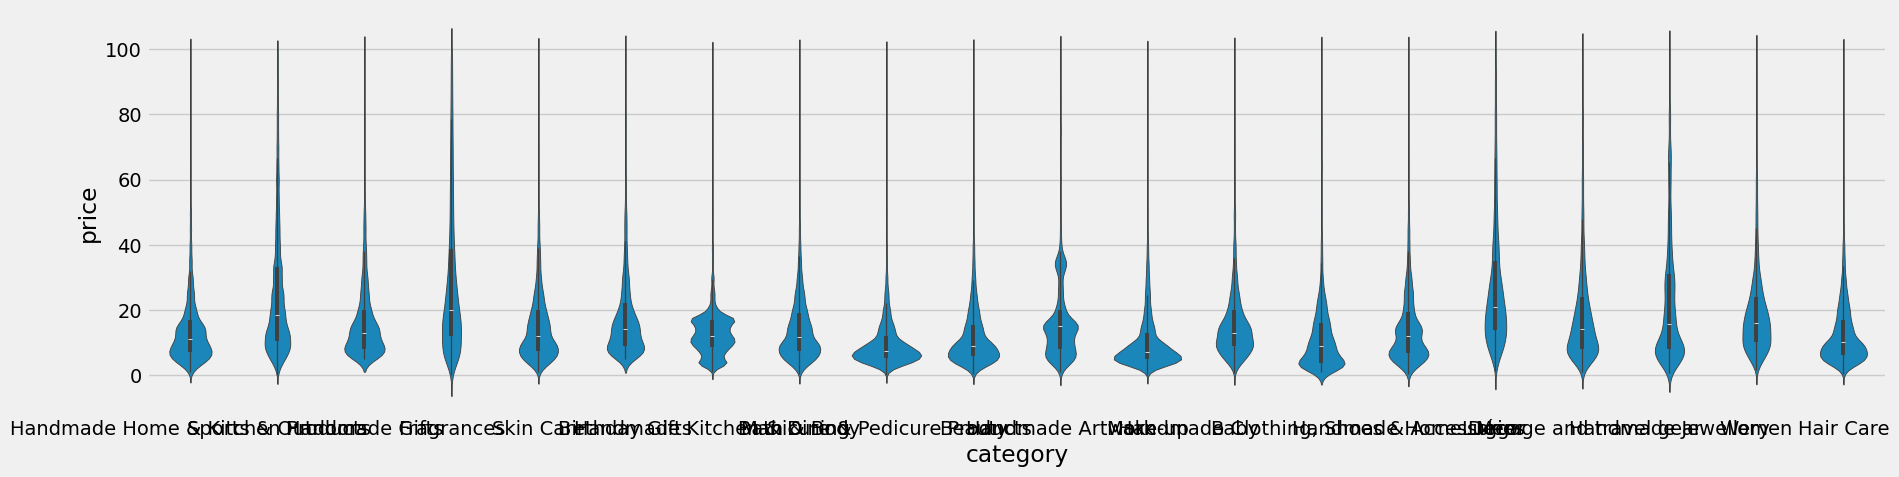

In [84]:
plt.figure(figsize=(20, 5))
sns.violinplot(data = top_cats2, x='category', y='price')
plt.show()
    

2. **Bar Charts**:
    - Create a bar chart comparing the average price of products for the top 10 product categories (based on count).
    - Which product category commands the highest average price? Don't filter here by top categories.

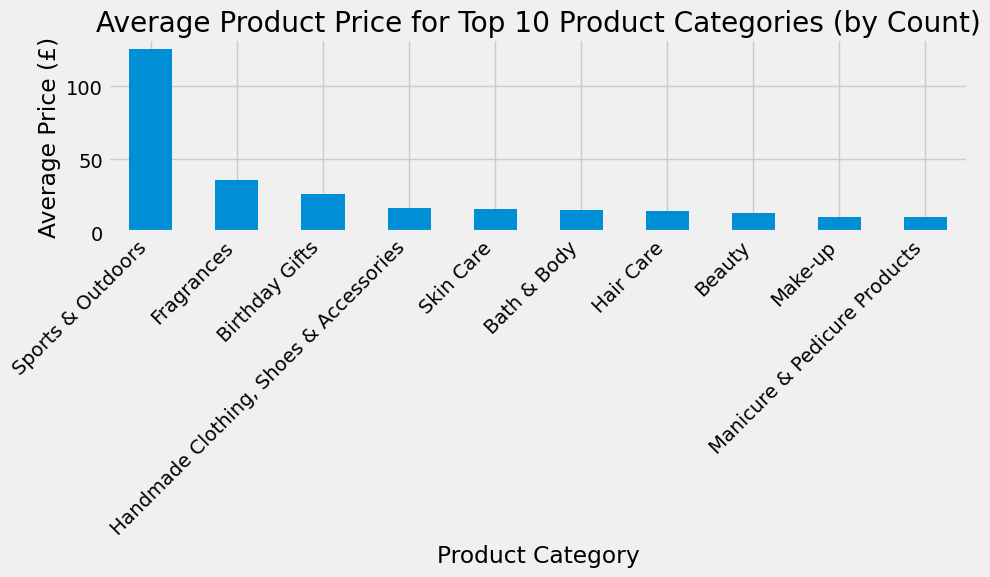

In [103]:
top10_categories = (df["category"].value_counts().head(10).index)
average_price_top10 = df.groupby("category")["price"].mean().sort_values(ascending = False)
average_price_top10 = df[df["category"].isin(top10_categories)]\
    .groupby("category")["price"].mean() \
    .sort_values(ascending=False)

plt.figure(figsize=(10,6))
average_price_top10.plot(kind="bar")
plt.title("Average Product Price for Top 10 Product Categories (by Count)")
plt.xlabel("Product Category")
plt.ylabel("Average Price (£)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()



3. **Box Plots**:
    - Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating from customers? Don't filter here by top categories.

In [105]:
print(df.columns)


Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')


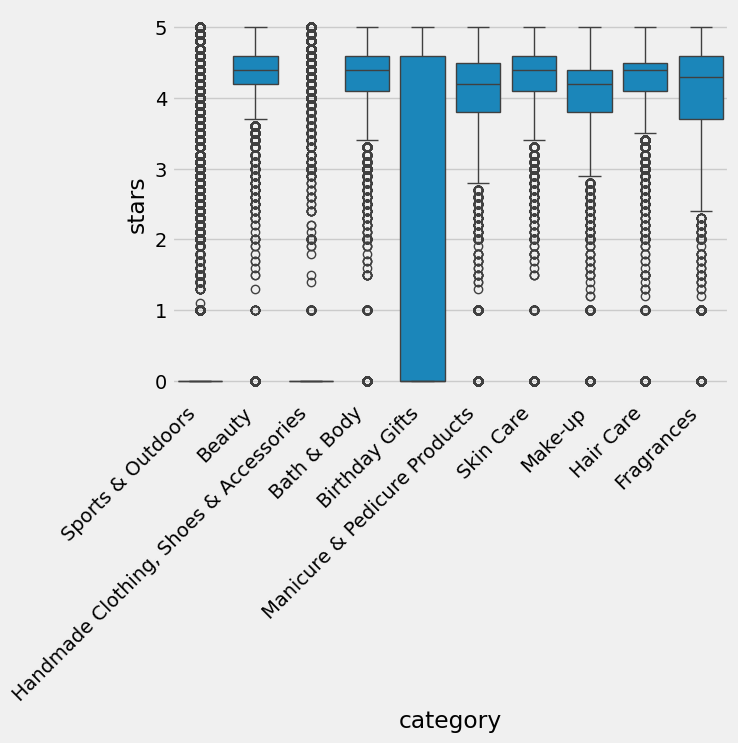

In [107]:
df_top10 = df[df["category"].isin(top10_categories)]
sns.boxplot(
    data=df_top10,
    x="category",
    y="stars",
    order=df_top10["category"].value_counts().head(10).index
)
plt.xticks(rotation=45, ha='right')
plt.show()

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.


1. **Correlation Coefficients**:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?

In [110]:
df = df[df["stars"] > 0]
df["stars"].corr(df["price"],method = "pearson")

np.float64(-0.004911823000752917)

there is not a significant correlation between price and stars since the pearson value is low. However, the negative sign tells us that with the price increase the stars tend to decrese slightly

2. **Visualizations**:
    - Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?
    - Use a correlation heatmap to visualize correlations between all numerical variables.
    - Examine if product prices typically follow a normal distribution using a QQ plot. 



<Axes: xlabel='stars', ylabel='price'>

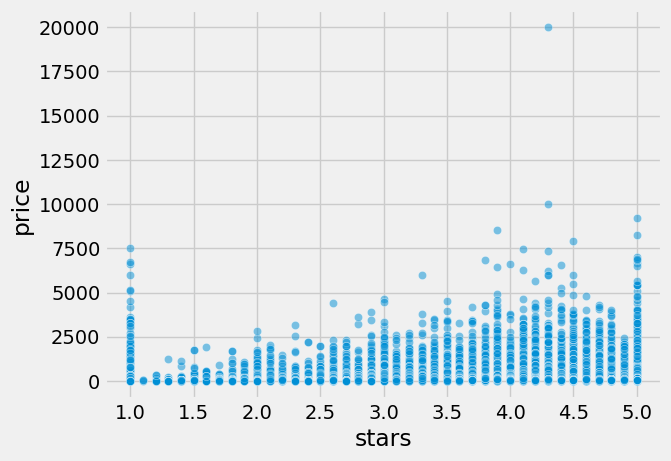

In [111]:
sns.scatterplot(data=df, x="stars", y="price", alpha=0.5)

<Axes: >

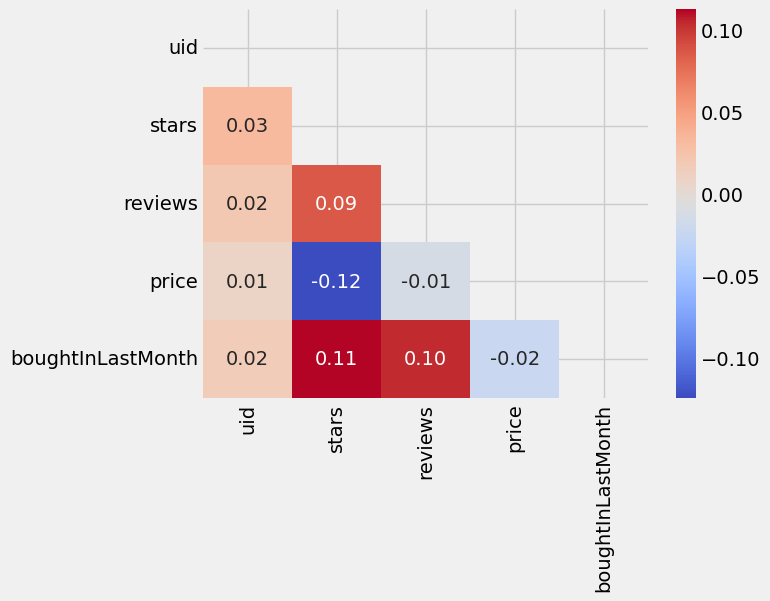

In [116]:
corr = num.corr()

mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(num.corr(), annot=True, mask=mask, cmap="coolwarm", fmt=".2f")


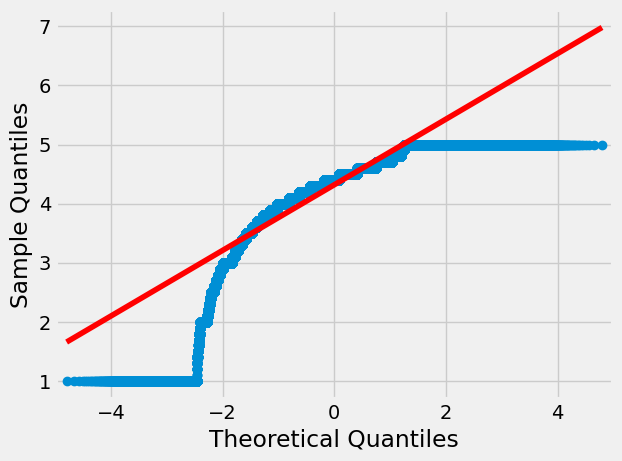

In [112]:
import statsmodels.api as sm
sm.qqplot(df['stars'], line='s'); # Q-Q plot to assess normality. 

the qq plot tells us that product prices dont usually follow a normal distribution as shown here.